In [7]:
# Extract the word right before the period (.) in Name
train["Title"] = train["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)

# Check counts, median Age, and survival rate per Title
title_summary = train.groupby("Title").agg(
    count=("Survived", "count"),
    median_age=("Age", "median"),
    survival_rate=("Survived", "mean")
).sort_values(by="count", ascending=False)

display(title_summary)

,count,median_age,survival_rate
Title,,,
Mr,517,30.0,0.156673
Miss,182,21.0,0.697802
Mrs,125,35.0,0.792000
Master,40,3.5,0.575000
Dr,7,46.5,0.428571
Rev,6,46.5,0.000000
Mlle,2,24.0,1.000000
Major,2,48.5,0.500000
Col,2,58.0,0.500000


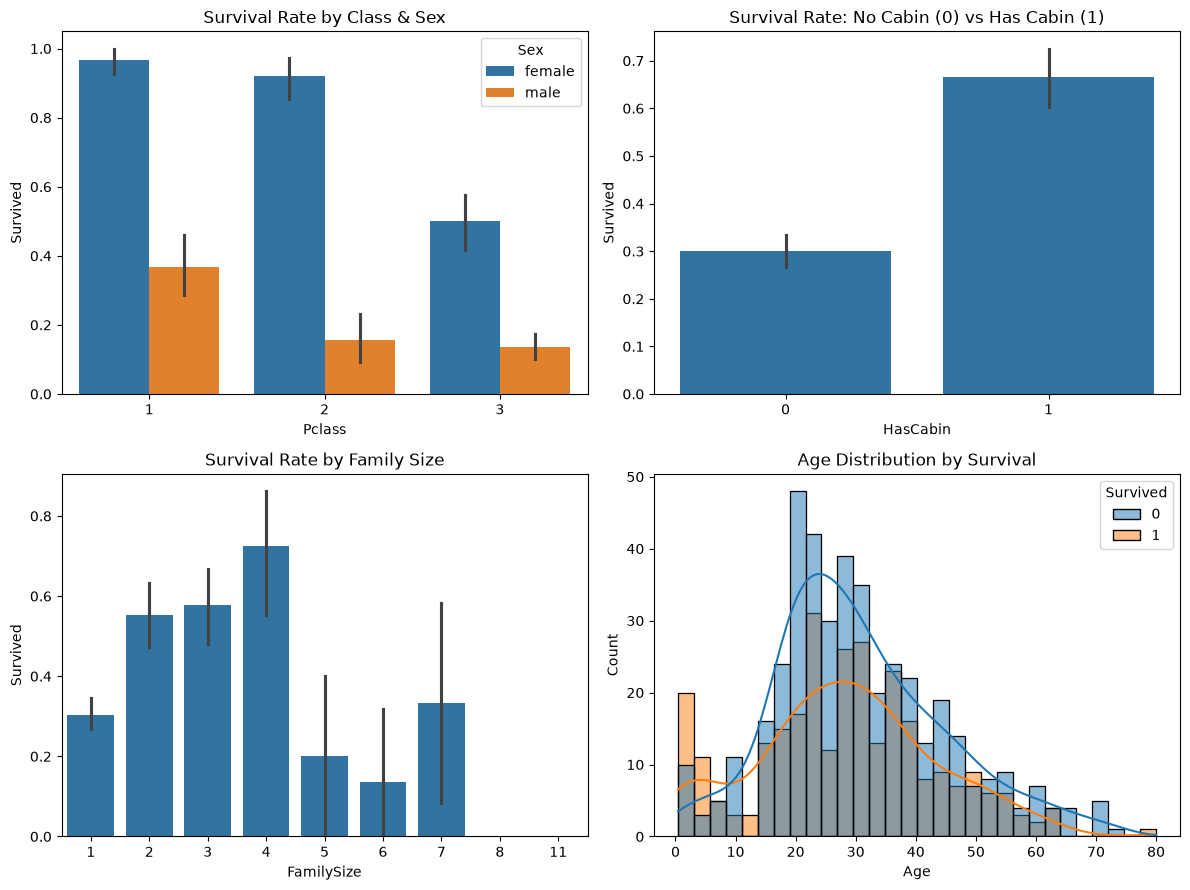

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Survival by Sex and Pclass ("Women and children first" + ticket class)
sns.barplot(data=train, x="Pclass", y="Survived", hue="Sex", ax=axes[0, 0])
axes[0, 0].set_title("Survival Rate by Class & Sex")

# 2. Is Cabin missingness itself a useful signal?
train["HasCabin"] = train["Cabin"].notnull().astype(int)
sns.barplot(data=train, x="HasCabin", y="Survived", ax=axes[0, 1])
axes[0, 1].set_title("Survival Rate: No Cabin (0) vs Has Cabin (1)")

# 3. Family size impact (solo travelers vs small families vs large families)
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
sns.barplot(data=train, x="FamilySize", y="Survived", ax=axes[1, 0])
axes[1, 0].set_title("Survival Rate by Family Size")

# 4. Age distribution for Survived vs Died
sns.histplot(data=train, x="Age", hue="Survived", kde=True, bins=30, ax=axes[1, 1])
axes[1, 1].set_title("Age Distribution by Survival")

plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import numpy as np

train = pd.read_csv("../data/train.csv")
display(train.head())
print(train.isnull().sum()[train.isnull().sum() > 0])
print(train["Survived"].value_counts(normalize=True).round(3))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Age         177
Cabin       687
Embarked      2
dtype: int64
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64
